Customers   :   1000 rows |  6 columns
Restaurants :    100 rows |  6 columns
Drivers     :    150 rows |  4 columns
Orders      :   6000 rows |  7 columns
Deliveries  :   5638 rows |  8 columns
Payments    :   5638 rows |  5 columns
Reviews     :   2255 rows |  4 columns
=== Missing Value Counts ===
Customers   : 0 missing values
Restaurants : 0 missing values
Drivers     : 0 missing values
Orders      : 0 missing values
Deliveries  : 0 missing values
Payments    : 0 missing values
Reviews     : 0 missing values


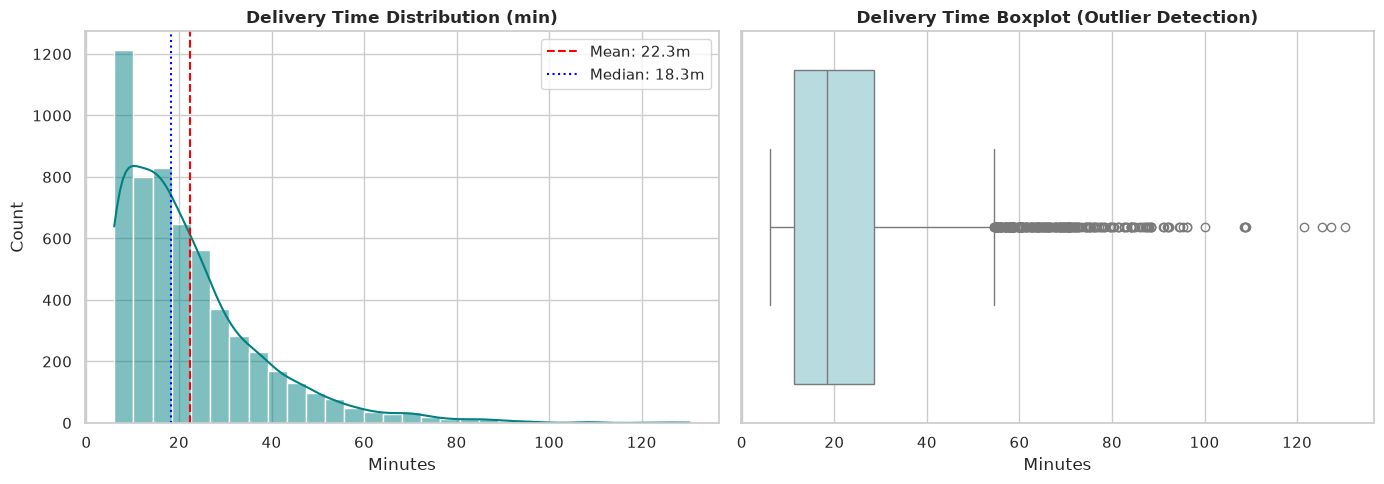

IQR: 17.30 mins | Total Outliers (> 54.5 mins): 247


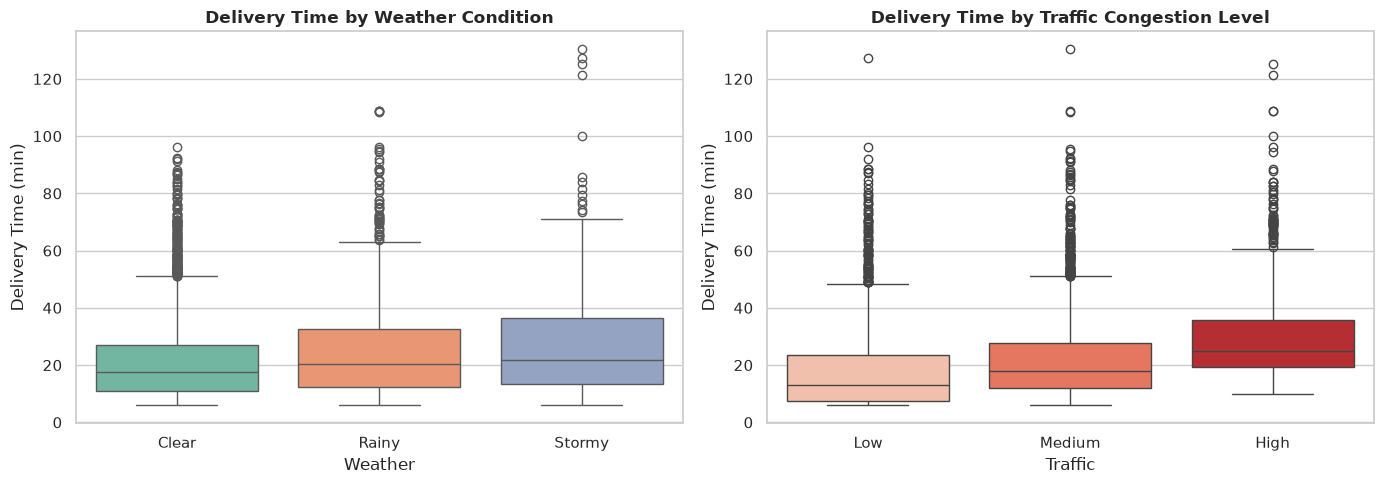

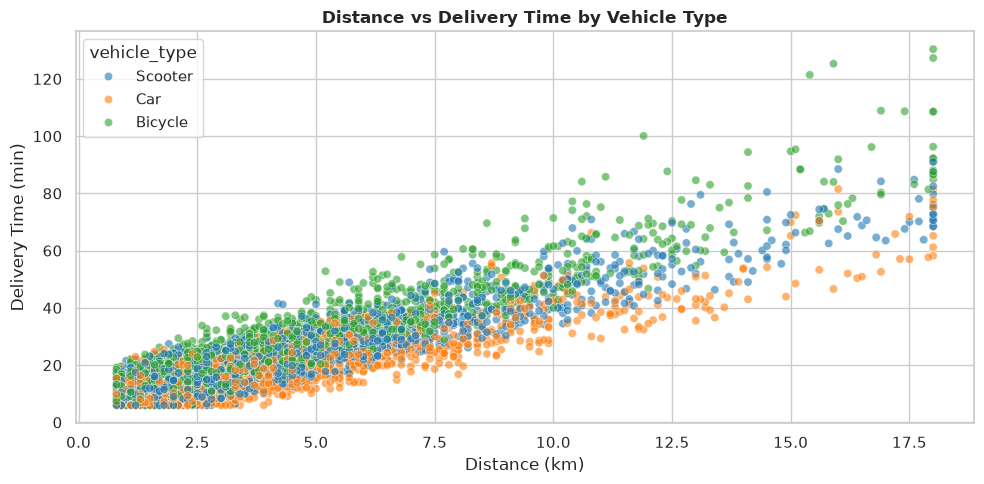

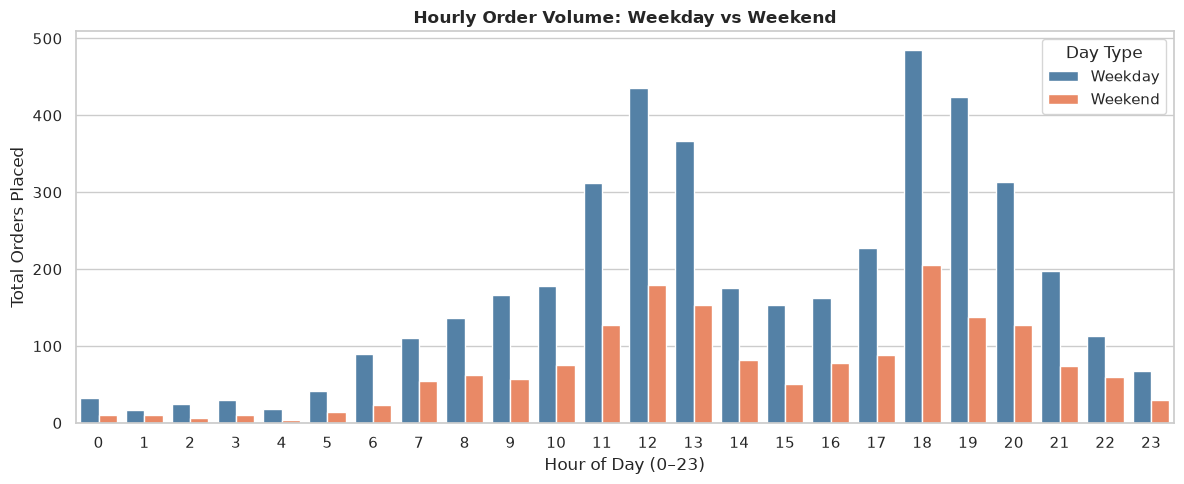

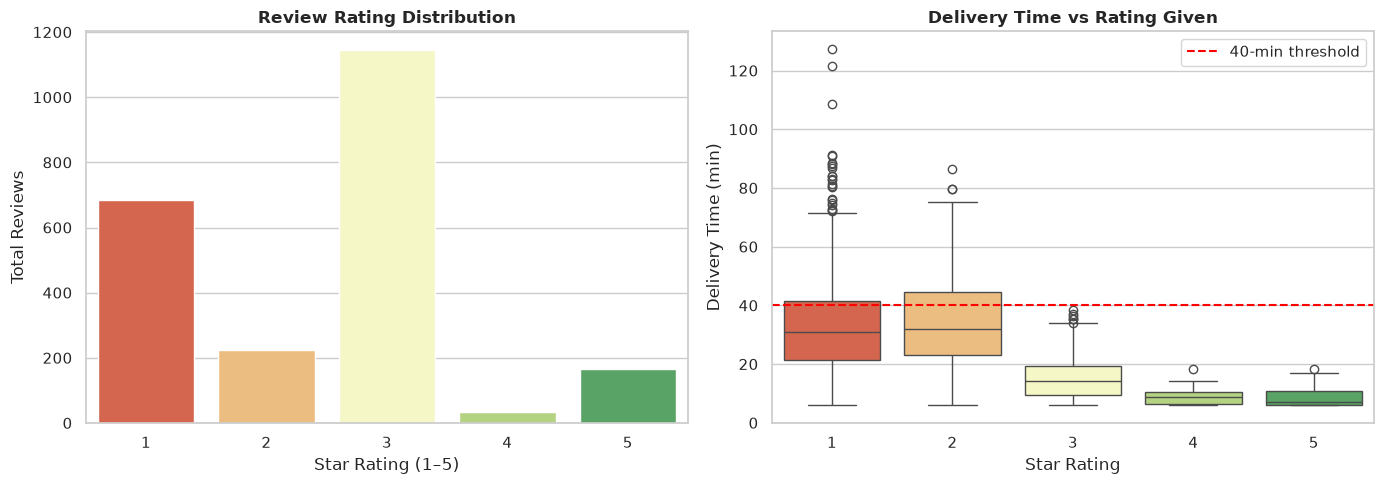

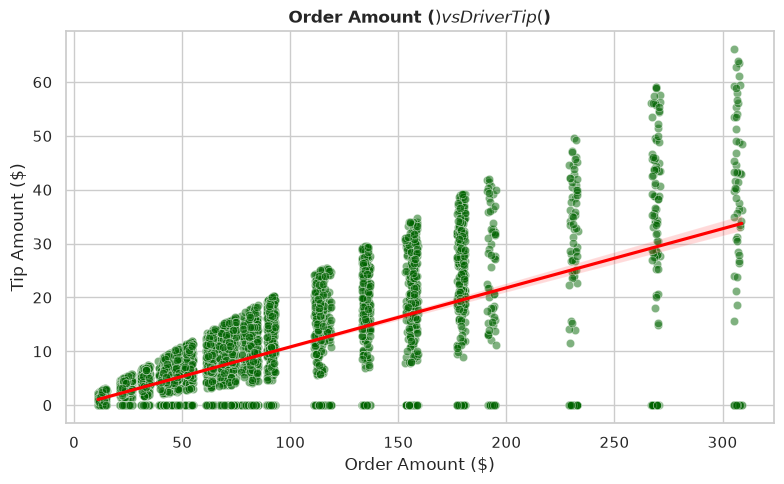

Pearson Correlation (Order Amount vs Tip): 0.668


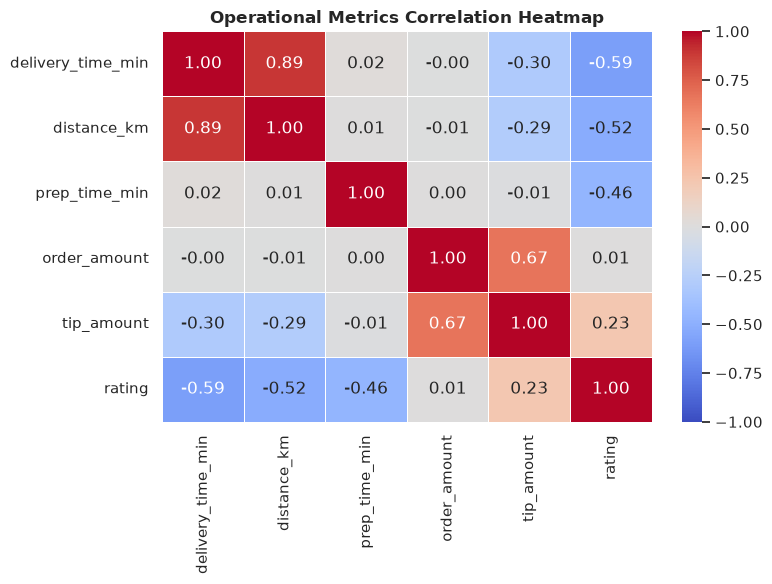

In [2]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

# %% [Cell 2: Data Loading]
# Load all 7 relational tables
customers = pd.read_csv('../data/raw/customers.csv')
restaurants = pd.read_csv('../data/raw/restaurants.csv')
drivers = pd.read_csv('../data/raw/drivers.csv')
orders = pd.read_csv('../data/raw/orders.csv')
deliveries = pd.read_csv('../data/raw/deliveries.csv')
payments = pd.read_csv('../data/raw/payments.csv')
reviews = pd.read_csv('../data/raw/reviews.csv')

tables = {
    'Customers': customers,
    'Restaurants': restaurants,
    'Drivers': drivers,
    'Orders': orders,
    'Deliveries': deliveries,
    'Payments': payments,
    'Reviews': reviews
}

for name, df in tables.items():
    print(f"{name:12}: {df.shape[0]:>6} rows | {df.shape[1]:>2} columns")

# %% [Cell 3: Missing Value Diagnostics]
print("=== Missing Value Counts ===")
for name, df in tables.items():
    nulls = df.isnull().sum()
    if nulls.sum() > 0:
        print(f"\n{name}:\n{nulls[nulls > 0]}")
    else:
        print(f"{name:12}: 0 missing values")

# %% [Cell 4: Target Variable Distribution - Delivery Time]
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

mean_time = deliveries['delivery_time_min'].mean()
median_time = deliveries['delivery_time_min'].median()

sns.histplot(deliveries['delivery_time_min'], kde=True, ax=ax[0], color='teal', bins=30)
ax[0].axvline(mean_time, color='red', linestyle='--', label=f'Mean: {mean_time:.1f}m')
ax[0].axvline(median_time, color='blue', linestyle=':', label=f'Median: {median_time:.1f}m')
ax[0].set_title('Delivery Time Distribution (min)', weight='bold')
ax[0].set_xlabel('Minutes')
ax[0].legend()

sns.boxplot(x=deliveries['delivery_time_min'], ax=ax[1], color='powderblue')
ax[1].set_title('Delivery Time Boxplot (Outlier Detection)', weight='bold')
ax[1].set_xlabel('Minutes')

plt.tight_layout()
plt.show()

# Outlier Calculation
q25 = deliveries['delivery_time_min'].quantile(0.25)
q75 = deliveries['delivery_time_min'].quantile(0.75)
iqr = q75 - q25
outliers = deliveries[(deliveries['delivery_time_min'] < (q25 - 1.5 * iqr)) | (deliveries['delivery_time_min'] > (q75 + 1.5 * iqr))]
print(f"IQR: {iqr:.2f} mins | Total Outliers (> {q75 + 1.5*iqr:.1f} mins): {len(outliers)}")

# %% [Cell 5: Operational Bottlenecks - Weather & Traffic]
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=deliveries, x='weather', y='delivery_time_min', ax=ax[0], palette='Set2')
ax[0].set_title('Delivery Time by Weather Condition', weight='bold')
ax[0].set_xlabel('Weather')
ax[0].set_ylabel('Delivery Time (min)')

traffic_order = ['Low', 'Medium', 'High'] if 'Low' in deliveries['traffic'].values else None
sns.boxplot(data=deliveries, x='traffic', y='delivery_time_min', order=traffic_order, ax=ax[1], palette='Reds')
ax[1].set_title('Delivery Time by Traffic Congestion Level', weight='bold')
ax[1].set_xlabel('Traffic')
ax[1].set_ylabel('Delivery Time (min)')

plt.tight_layout()
plt.show()

# %% [Cell 6: Vehicle Performance - Distance vs Delivery Time]
deliv_driver = deliveries.merge(drivers[['driver_id', 'vehicle_type']], on='driver_id', how='left')

plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=deliv_driver,
    x='distance_km',
    y='delivery_time_min',
    hue='vehicle_type',
    alpha=0.6,
    palette='tab10'
)
plt.title('Distance vs Delivery Time by Vehicle Type', weight='bold')
plt.xlabel('Distance (km)')
plt.ylabel('Delivery Time (min)')
plt.tight_layout()
plt.show()

# %% [Cell 7: Temporal Ordering Patterns - Hourly Demand]
orders['order_timestamp'] = pd.to_datetime(orders['order_timestamp'])
orders['hour'] = orders['order_timestamp'].dt.hour
orders['is_weekend'] = orders['order_timestamp'].dt.dayofweek.isin([5, 6])

plt.figure(figsize=(12, 5))
sns.countplot(data=orders, x='hour', hue='is_weekend', palette={False: 'steelblue', True: 'coral'})
plt.title('Hourly Order Volume: Weekday vs Weekend', weight='bold')
plt.xlabel('Hour of Day (0–23)')
plt.ylabel('Total Orders Placed')
plt.legend(['Weekday', 'Weekend'], title='Day Type')
plt.tight_layout()
plt.show()

# %% [Cell 8: Review Ratings vs Delivery Duration]
order_reviews = reviews.merge(deliveries[['order_id', 'delivery_time_min']], on='order_id', how='left')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=reviews, x='rating', palette='RdYlGn', ax=ax[0])
ax[0].set_title('Review Rating Distribution', weight='bold')
ax[0].set_xlabel('Star Rating (1–5)')
ax[0].set_ylabel('Total Reviews')

sns.boxplot(data=order_reviews, x='rating', y='delivery_time_min', palette='RdYlGn', ax=ax[1])
ax[1].axhline(40, color='red', linestyle='--', label='40-min threshold')
ax[1].set_title('Delivery Time vs Rating Given', weight='bold')
ax[1].set_xlabel('Star Rating')
ax[1].set_ylabel('Delivery Time (min)')
ax[1].legend()

plt.tight_layout()
plt.show()

# %% [Cell 9: Order Amount vs Driver Tip Correlation]
order_payments = payments.merge(orders[['order_id', 'order_amount']], on='order_id', how='left')

plt.figure(figsize=(8, 5))
sns.scatterplot(data=order_payments, x='order_amount', y='tip_amount', alpha=0.5, color='darkgreen')
sns.regplot(data=order_payments, x='order_amount', y='tip_amount', scatter=False, color='red')
plt.title('Order Amount ($) vs Driver Tip ($)', weight='bold')
plt.xlabel('Order Amount ($)')
plt.ylabel('Tip Amount ($)')
plt.tight_layout()
plt.show()

corr_tip = order_payments['order_amount'].corr(order_payments['tip_amount'])
print(f"Pearson Correlation (Order Amount vs Tip): {corr_tip:.3f}")

# %% [Cell 10: Multivariate Correlation Matrix]
merged_eda = (
    deliveries.merge(orders, on='order_id', how='inner')
    .merge(payments, on='order_id', how='inner')
    .merge(reviews, on='order_id', how='left')
)

numeric_cols = ['delivery_time_min', 'distance_km', 'prep_time_min', 'order_amount', 'tip_amount', 'rating']
corr_matrix = merged_eda[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Operational Metrics Correlation Heatmap', weight='bold')
plt.tight_layout()
plt.show()